# Decoder stability across seeds -- CosMx pancreas (melton25)

The CosMx counterpart of [`notebooks/legnini_23/4_a_decoder_stability.ipynb`](../legnini_23/4_a_decoder_stability.ipynb),
running the *same* code: every function both notebooks use now lives in
[`src/decoder_stability.py`](../../src/decoder_stability.py), because the point of having two of
these is a like-for-like comparison and that only holds if the gene-selection code is shared
rather than copied.

**Two seed sweeps, five seeds each**, differing only in masking granularity:

| arm | registry task | `mask_strategy` | rate | sweep | checkpoints |
|---|---|---|---|---|---|
| `cell` | `melton25/node_reg` | `node` | 0.10 of the cells | [`f0ob49zb`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/f0ob49zb) | `melton25_revision/seed_stability_cell/` |
| `gene` | `melton25/node_reg_genemask` | `gene` | 0.25 of each cell's genes | [`4ztsppu8`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/4ztsppu8) | `melton25_revision/seed_stability_gene/` |

Flip the `MASKING` switch below and re-run from there; nothing after it is arm-specific.

**These are new sweeps, not `best_recon/`.** `results/melton25_revision/best_recon/` already holds
five seed models -- but they were trained by
`scripts/melton_jimenez_25/celltype_reconstruction_mse.py` as a plain per-seed retrain, not as a
wandb sweep, and only under cell masking. The two sweeps here are registered runs with a
gene-masking counterpart, which is what the masking-granularity comparison needs. They do
inherit `best_recon`'s configuration: **n_embed=128 with GaussianNLL**, sweep `sio2fsjm`'s winning
trial, *not* the registry defaults of n_embed=16 / SmoothL1. That is not optional --
`CombinedModel.load` uses `strict=False`, so loading these checkpoints against the registry
defaults returns a silently mis-shaped model instead of raising. `MELTON25_BEST` below reapplies
it.

**This notebook is heavy**: 386727 cells x 979 genes, and `get_model_output` materialises a
386727 x 1600 attention matrix (~2.5 GB) per seed (dropped immediately). Run it on a GPU node
inside the interscale container (`run_jupyter_interscale_cu128.sbatch`), not on a login node.

In [1]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import issparse
import interscale

from pathlib import Path
from functools import partial

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'

DATA = "melton25"

HPC cluster


In [3]:
import yaml
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]

## Load data

In [4]:
COSMX = f'{BASE_DIR_PROJECT}/data/{DATA}.h5ad'
adata = sc.read_h5ad(COSMX)
adata

AnnData object with n_obs × n_vars = 386727 × 979
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.GCG', 'Max.GCG', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'cell_ID', 'condition', 'slide', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_NegPrb', 'log1p_total_counts_NegPrb', 'pct_counts_NegPrb', 'n_genes', 'cell_type_coarse', 'CellTypes_max', 'slide_fov', 'slide_condition', 'split', 'split_0', 'split_1', 'split_2', 'globalX', 'globalY', 'sliding_window_square', 'sliding_window_h', 'sliding_window_v'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_fov'
    layers: 'counts', None (.X)

In [5]:
# melton25 keeps the expression the decoders reconstruct in .X (cfg.dataset.layer_key is None);
# layers holds raw counts only. That is the opposite of legnini23, where .X is counts and the
# target is layers['log1p_norm'] -- so nothing here may assume a layer name. `target_layer`
# below exposes .X under an explicit key instead, because gene_loadings/get_genes_dim both take
# a layer NAME and raise on None.
print('layers      :', list(adata.layers))
print('X   max     :', adata.X.max())
print('counts max  :', adata.layers['counts'].max())
print('zero-count cells:', int((adata.X.sum(1) == 0).sum()))
print('genes       :', adata.n_vars)
print()
print(adata.obs['cell_type_coarse'].value_counts())
print()
print(adata.obs['split'].value_counts())

layers      : ['counts', None]
X   max     : 4.8127866
counts max  : 325
zero-count cells: 0
genes       : 979

cell_type_coarse
Acinar         184395
Ductal         127936
Fibroblasts     25194
Immune          14578
Alpha           10318
Beta             9028
Endothelial      8528
Endocrine        3658
Mast             3092
Name: count, dtype: int64

split
test     151595
val      126421
train    108711
Name: count, dtype: int64


In [6]:
# The graphs the models were trained on: one per sliding_window_square, scoped per slide_fov.
sizes = adata.obs['sliding_window_square'].value_counts()
sizes = sizes[sizes > 0]
print(f"{len(sizes)} windows | largest {sizes.max()} | median {int(sizes.median())} cells")
sizes.head()

596 windows | largest 1600 | median 631 cells


sliding_window_square
3_25_window_4    1600
2_21_window_4    1498
3_6_window_4     1452
2_22_window_7    1440
3_11_window_8    1421
Name: count, dtype: int64

## Load trained models

In [7]:
import sys

project_root = Path(BASE_DIR_REPO)  # InterScale_reproducibility, for `from src.* import ...`
sys.path.insert(0, str(project_root))

# The interscale package is a SIBLING of InterScale_reproducibility, not a subdirectory of it.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "melton25"

# ---------------------------------------------------------------------------------------------
# WHICH MASKING ARM TO LOAD.  Flip this and re-run from here; nothing below is arm-specific.
#
#   "cell"  whole cells are blanked and all G genes of them are scored  (mask_strategy "node")
#   "gene"  individual (cell, gene) entries are blanked and only those are scored
#
# The two sweeps are matched: same five seeds, same schedule, same architecture (sweep
# sio2fsjm's winning trial), both trained with MASK_VALUE = -1. They differ only in masking
# granularity and its rate, so a difference in how stable the gene loadings are across seeds is
# attributable to that.
#
# The rate is not the same NUMBER in the two arms because it is not the same QUANTITY: 0.10 of
# the CELLS against 0.25 of every cell's GENES. 0.10 is best_recon's own value; 0.25 is carried
# over from legnini23, where it was measured -- it has NOT been swept on this dataset, whose
# 979-gene panel offers an order of magnitude more within-cell redundancy for gene masking to
# exploit than legnini23's 88. If the gene arm loses here, sweep the rate before concluding
# anything about granularity.
# ---------------------------------------------------------------------------------------------
# Reading the env var lets the same notebook be executed headlessly once per arm
# (scripts/melton_jimenez_25/run_decoder_stability.sh); interactively it is just "cell".
MASKING = os.environ.get("MASKING", "cell")  # "cell" | "gene"

ARMS = {
    "cell": {
        "task": "node_reg",
        "sweep_id": "f0ob49zb",  # config_files/sweeps/seed_cell_masking_melton25.yaml
        "models_subdir": "seed_stability_cell",
        # The registry default for this pair is 0.3; the sweep pinned 0.1. It changes no tensor
        # shape, so load() would succeed either way -- which is exactly why omitting it would go
        # unnoticed and the config recorded here would not be the one that trained.
        "overrides": {"dataset.mask_percentage": 0.1},
    },
    "gene": {
        "task": "node_reg_genemask",
        "sweep_id": "4ztsppu8",  # config_files/sweeps/seed_gene_masking_melton25.yaml
        "models_subdir": "seed_stability_gene",
        # Likewise below the task file's 0.5.
        "overrides": {"dataset.mask_percentage": 0.25},
    },
}
assert MASKING in ARMS, f"MASKING must be one of {sorted(ARMS)}"
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]

MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "melton25_revision" / ARM["models_subdir"]
# Per-arm, so the two arms' per-gene CSVs sit side by side instead of overwriting each other.
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"rec_seed_stablity_{MASKING}"

assert REGISTRY.exists(), f"registry not found: {REGISTRY}"
assert MODELS_DIR.exists(), (
    f"checkpoint dir not found: {MODELS_DIR}\n"
    f"Train it with:  SWEEP_ID={SWEEP_ID} sbatch scripts/run.sh {DATASET} {TASK} "
    f"--sweep_cfg config_files/sweeps/seed_{MASKING}_masking_melton25.yaml "
    f"--sweep_goal robustness --metric val_concordance_corr --count 5"
)
print(f"masking     {MASKING} (task {TASK}, sweep {SWEEP_ID})")
print(f"registry    {REGISTRY}\ncheckpoints {MODELS_DIR}\nresults     {RESULTS_DIR}")

masking     gene (task node_reg_genemask, sweep 4ztsppu8)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/seed_stability_gene
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25/rec_seed_stablity_gene


In [8]:
import wandb

from interscale.tl.utils import get_model_filename_prefix, set_full_reproducibility
from interscale.tl import remove_zero_expression_cells
from src.wandb import Wandb_evaluation

# Shared with notebooks/legnini_23/4_decoder_stability.ipynb -- same selection code, both
# datasets. See src/decoder_stability.py.
from src.decoder_stability import (
    GROUP_COLORS,
    build_cfg as _build_cfg,
    collect_gene_sets,
    expected_intersection,
    intersection_by_k,
    intersection_tail_probability,
    local_global_split,
    overlap_matrix,
    per_gene_metrics,
    plot_intersection_by_k,
    plot_membership,
    plot_tail_prob_by_k,
    run_seed_inference,
    tail_prob_by_k,
    target_layer,
)

wandb.login()

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.


wandb: Currently logged in as: francesca-drummer to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Load WandB sweep

Five seeds, every other model parameter identical. `Wandb_evaluation` hardcodes
entity/project to `francesca-drummer/InterScale_hyperparameter_sweep`, which is where
`main_sweep.py` registers sweeps by default -- so `SWEEP_ID` alone identifies the arm.

In [9]:
# NOT `wandb = ...`: that name is the wandb module, imported above, and rebinding it is what
# makes `wandb.Api(timeout=60)` raise AttributeError further down. The first argument is only a
# label.
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)

In [10]:
sweep_df = sweep_eval.get_dataframe()
sweep_df

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,vfmmck27,dual_melton25_genemask_regr_node_40_GCN_self-a...,40,finished,0.25,gene,0.25,None,None,173,769318,-0.202720,0.000133
1,dyyez8ph,dual_melton25_genemask_regr_node_41_GCN_self-a...,41,finished,0.25,gene,0.25,None,None,174,769318,-13.166381,0.000293
2,tivuq7e2,dual_melton25_genemask_regr_node_42_GCN_self-a...,42,finished,0.25,gene,0.25,None,None,177,769318,-12.804805,0.000348
3,48u61bu3,dual_melton25_genemask_regr_node_43_GCN_self-a...,43,finished,0.25,gene,0.25,None,None,178,769318,-0.911437,0.000069
4,m9pz5icq,dual_melton25_genemask_regr_node_44_GCN_self-a...,44,finished,0.25,gene,0.25,None,None,177,769318,-3.202423,0.000028


## Model inference

Load each of the five seed models, run inference, and keep

- `local_emb[seed]` / `global_emb[seed]` &mdash; the two embeddings, `(n_cells, n_embed)`
- `models[seed]` &mdash; the loaded `CombinedModel`, for the gene-loading section below
- `performance[seed]` &mdash; per-gene reconstruction scores, also written to
  `results/melton25/rec_seed_stablity_{MASKING}/model_{seed}_performance.csv`

The models are loaded from disk rather than from wandb artifacts: both sweeps pinned
`model.save`, so all ten checkpoints already sit on lustre.

**The seed cannot be read off `run.config['optim']['seed']`.** `main_sweep.py` calls
`wandb.init(config=cfg)` *before* `apply_sweep_config`, so the nested config wandb stored is the
base config &mdash; seed 44 for all five runs, which is also why every run is named
`..._44_...`. Only the flattened `run.config['optim.seed']` (what `sweep_df["seed"]` reads)
carries the trial's actual value, and it is what `build_cfg` applies below.

In [11]:
# Sweep sio2fsjm's winning trial (run ycjcovv2) -- i.e. what these checkpoints were actually
# trained with, and what `results/melton25_revision/best_recon/` holds. It has to be reapplied
# on top of the resolved registry pair: the registry alone gives n_embed=16 / SmoothL1, which
# builds a differently shaped module, and CombinedModel.load uses strict=False -- so the
# mismatch comes back as a silently wrong model, not an error.
#
# Keep in sync with scripts/melton_jimenez_25/celltype_reconstruction_mse.py::BEST,
# config_files/sweeps/seed_{cell,gene}_masking_melton25.yaml and
# config_files/sweeps/component_ablation_melton25.yaml.
#
# `dataset.pct_mask_nodes` is deliberately absent: that key no longer exists (it was split into
# dataset.mask_strategy + dataset.mask_percentage), and apply_sweep_config does not allow new
# keys, so passing it raises. The rate lives in ARM["overrides"] instead, because it is the one
# hyperparameter the two arms do not share.
#
# optim.n_epochs is also absent, so both arms inherit the registry default (100) that
# best_recon/ was trained under. Unlike legnini23 -- where nothing ever early-stops and 100
# undertrains badly -- EarlyStopping does fire on this dataset, around epoch 40 (min_epochs 40,
# patience 5), so the cap is not what ends these runs. Check `stopped_epoch` per trial anyway:
# early stopping has been observed to truncate arms unequally, which would confound the
# comparison.
MELTON25_BEST = {
    "optim.loss": "GaussianNLL",
    "model.n_embed": 128,
    "model.local_component.parameters.hidden_dim": 256,
    "model.local_component.parameters.num_layers": 1,
    "model.local_component.parameters.dropout_local": 0.0,
    "model.global_component.parameters.num_layers": 2,
    "model.global_component.parameters.n_heads": 2,
    "model.global_component.parameters.dim_feedforward": 256,
    "model.global_component.parameters.dropout_global": 0.0,
    "dataset.batch_size": 8,
    "optim.lr": 0.005,
    "optim.wd": 0.01,
    "optim.lr_warmup": 20,
    "optim.monitor": "val_concordance_corr",
}

# optim.seed is not cosmetic: get_model_filename_prefix puts it in the checkpoint name, which is
# what makes the five models separable when load() picks the file. The same prefix carries
# dataset.name, which the registry sets to melton25_genemask for the gene arm -- so the two
# arms' checkpoints are distinguishable even before the directory split.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=MODELS_DIR,
    sweep_overrides=MELTON25_BEST,
    overrides=ARM["overrides"],
)

In [12]:
# Training filtered zero-expression cells; inference has to filter identically or the per-window
# graphs handed to the model are not the graphs it was trained on. Unlike legnini23 there is no
# later cell that repoints .X, so the helper can read .X directly.
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)
assert len(SEEDS) == 5, (
    f"{len(SEEDS)} finished runs in sweep {SWEEP_ID}, expected 5 -- the agent is still running "
    f"or a trial failed. Resume with the same SWEEP_ID; a grid sweep does not repeat trials."
)

cfg0 = build_cfg(SEEDS[0])
layer_key = target_layer(adata, cfg0)
window_key = cfg0.dataset.sample_key[0]
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

# Every checkpoint must be on disk before the loop starts -- load() with a missing file is a
# slower and less obvious failure than this.
missing = [
    s for s in SEEDS
    if not (MODELS_DIR / f"{get_model_filename_prefix(build_cfg(s), True, True)}model.pt").exists()
]
assert not missing, f"no checkpoint for seeds {missing} in {MODELS_DIR}"

# Below max_seq_len, tl/padding.py random-subsamples each graph every call instead of erroring,
# so the predictions would come from a graph the model never saw.
sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} window is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")
print(f"n_embed {cfg0.model.n_embed} | loss {cfg0.optim.loss} | "
      f"mask {cfg0.dataset.mask_strategy} @ {cfg0.dataset.mask_percentage} | "
      f"target layer '{layer_key}'")

# Ground truth is what the decoders were trained to reconstruct.
_t = adata.layers[layer_key]
y_true = np.asarray(_t.todense() if issparse(_t) else _t, dtype=np.float64)
print(f"y_true {y_true.shape} ({y_true.nbytes / 1e9:.1f} GB)")

Nr. of zero expression cells: 0
seeds: [40, 41, 42, 43, 44]
applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']
applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'opti

applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']
applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']
applied sweep parameters: ['dataset.

y_true (386727, 979) (3.0 GB)


In [13]:
# Writes obsm[f"{seed}_local_emb"] / obsm[f"{seed}_global_emb"] and
# layers[f"{seed}_y_pred_local"] / layers[f"{seed}_y_pred_global"] into adata, plus one per-gene
# csv per seed under RESULTS_DIR. The seed prefix is what lets the gene-loading section below
# revisit any seed, not only the last one inferred.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    MODELS_DIR,
    RESULTS_DIR,
    y_true=y_true,
    repro_seed=40,
)

applied sweep parameters: ['dataset.batch_size', 'model.global_component.parameters.dim_feedforward', 'model.global_component.parameters.dropout_global', 'model.global_component.parameters.n_heads', 'model.global_component.parameters.num_layers', 'model.local_component.parameters.dropout_local', 'model.local_component.parameters.hidden_dim', 'model.local_component.parameters.num_layers', 'model.n_embed', 'optim.loss', 'optim.lr', 'optim.lr_warmup', 'optim.monitor', 'optim.wd']


Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/seed_stability_gene/dual_melton25_genemask_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown


Load GEX from .X
INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


...

INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  


INFO     Creating graph using `None` transform and `1` libraries.                                                  



seed 44: wrote model_44_performance.csv (7832 rows)
  per-gene medians on the test split:
               r2       mse   pearson  cosine_sim
decoder                                          
global  -6.310124  0.255478  0.000682   -0.023074
local   -6.481542  0.240718  0.001667    0.016206

embeddings: local (386727, 128), global (386727, 128) per seed


In [14]:
# Test-split medians per seed, both decoders. Medians, not means: a handful of low-variance
# genes drive mean R2 to -1e2 and make it useless as a summary.
summary = pd.concat(
    {s: performance[s].query("split == 'test'")
                      .groupby("decoder")[["r2", "r2_offset_corrected", "pearson", "cosine_sim", "mse"]]
                      .median()
     for s in SEEDS},
    names=["seed"],
)
print(summary.to_string())
print()
print("across-seed spread (SD of the per-seed medians):")
print(summary.groupby("decoder").std(ddof=1).to_string())

                    r2  r2_offset_corrected       pearson  cosine_sim       mse
seed decoder                                                                   
40   global  -0.644075            -0.087171  6.128978e-05    0.010679  0.060367
     local   -0.917334            -0.405451 -1.381891e-03   -0.000836  0.065559
41   global  -6.195043            -2.719351  1.662181e-03    0.007815  0.251005
     local   -7.408293            -3.884939 -9.526804e-07   -0.004334  0.274183
42   global  -6.973352            -2.564403  8.638848e-04    0.019532  0.272842
     local   -7.443005            -3.817205 -1.114600e-03    0.004579  0.273455
43   global  -0.585890            -0.088072 -4.881866e-04    0.031795  0.059945
     local   -1.639763            -0.805786  2.083574e-04   -0.012290  0.096907
44   global  -6.310124            -2.472793  6.821385e-04   -0.023074  0.255478
     local   -6.481542            -3.426723  1.667190e-03    0.016206  0.240718

across-seed spread (SD of the per-seed 

## Gene loadings

`collect_gene_sets` runs `gene_loadings` -> `calculate_dim_importance` -> `get_genes_dim` per
seed, over all 128 dimensions, ranked by `loading_x_sd`.

Note it standardizes the **local** loadings by the **local** embedding's std.
`DualDecoderCombinedModule.predict_local` decodes the local embedding through the local decoder,
so using the global embedding's std there rescales every local dimension by the wrong constant,
which changes the dimension ranking and therefore which genes are selected. The legnini notebook
used to pass the global key on both sides; that is fixed in the shared helper, so neither
notebook's local sets reproduce the pre-refactor run.

In [15]:
# The genes the publication figure reports for this dataset: panel F, left = local embeddings,
# right = global embeddings. All 49 are in the 979-gene CosMx panel, so a gene missing from a
# seed's set was not recovered rather than not available.
#
# The four bolded in the figure -- GLUL, INS, REG1A (local) and IL32, IGF1R, C1QC (global) --
# are the ones the paper calls out; they are not treated specially here, but they are the rows
# to look at first in the membership plots.
TRUE_LOCAL_GENES = [
    'BTG1', 'CD44', 'ETV5', 'GLUL', 'H2AZ1', 'MT1X', 'CYSTM1', 'LDLR', 'HLA-A', 'TPM2', 'APP',
    'SPRY2', 'TUBB', 'DST', 'CUZD1', 'PTGES3', 'RARRES2', 'SRC', 'INS', 'CXCL2', 'REG1A',
    'H4C3', 'GDF15', 'NEAT1', 'GPX1',
]
TRUE_GLOBAL_GENES = [
    'CDKN1A', 'FABP5', 'MIF', 'HSP90AB1', 'TNFRSF12A', 'IL12RB1', 'SPP1', 'RPL22', 'PDGFD',
    'GPX3', 'MEG3', 'BTG1', 'IL32', 'IGFBP7', 'HLA-A', 'CALM3', 'TPM1', 'IGF1R', 'HLA-E',
    'GDF15', 'TAGLN', 'IL10RB', 'NDRG1', 'C1QC',
]

# The pool a selection could have drawn from. NOT the whole 979-gene panel: min_frac=0.1 below
# removes every gene expressed in under 10% of cells before any ranking happens, so those genes
# were never candidates and counting them inflates the pool -- which deflates the chance-overlap
# baselines that every stability claim here is read against.
#
# enforce_specificity=True narrows the effective pool further, per dimension, in a way that has
# no single number. So POOL is an UPPER bound on the candidate set, and the plotted random
# expectation is correspondingly a LOWER bound on chance overlap. Read the observed overlap as
# beating chance only when it clears the baseline comfortably.
# Defined here rather than next to the other selection settings because the pool has to be
# computed before it; collect_gene_sets below is passed this same value, and the two MUST agree
# or the baselines describe a different candidate set than the one that was selected from.
MIN_FRAC = 0.1

_X = adata.layers[layer_key]
_frac = np.asarray((_X > 0).mean(axis=0)).ravel()
POOL = int((_frac >= MIN_FRAC).sum())
print(f"panel {adata.n_vars} genes -> {POOL} pass min_frac={MIN_FRAC} "
      f"({POOL / adata.n_vars:.0%} of the panel)")

panel = set(adata.var_names)
for name, genes in [("local", TRUE_LOCAL_GENES), ("global", TRUE_GLOBAL_GENES)]:
    absent = [g for g in genes if g not in panel]
    assert not absent, f"{name} publication genes not in the panel: {absent}"
    print(f"{name:6s}: {len(genes)} published genes, all in the {POOL}-gene panel")
print("shared between the two published lists:",
      sorted(set(TRUE_LOCAL_GENES) & set(TRUE_GLOBAL_GENES)))

panel 979 genes -> 217 pass min_frac=0.1 (22% of the panel)
local : 25 published genes, all in the 217-gene panel
global: 24 published genes, all in the 217-gene panel
shared between the two published lists: ['BTG1', 'GDF15', 'HLA-A']



60% cumulative variance reached with 54 dimensions:
Embedding dimensions (sorted by importance):
[7, 116, 30, 71, 80, 28, 122, 27, 58, 36, 70, 60, 14, 39, 32, 11, 13, 117, 64, 34, 86, 49, 85, 44, 24, 25, 40, 17, 37, 0, 2, 52, 16, 96, 63, 102, 89, 114, 42, 1, 69, 118, 119, 68, 88, 5, 82, 15, 78, 33, 18, 83, 113, 90]

60% cumulative variance reached with 34 dimensions:
Embedding dimensions (sorted by importance):
[7, 126, 39, 52, 3, 66, 116, 13, 36, 102, 65, 121, 80, 27, 114, 44, 120, 2, 69, 71, 91, 49, 94, 4, 70, 122, 18, 110, 30, 40, 83, 25, 112, 34]


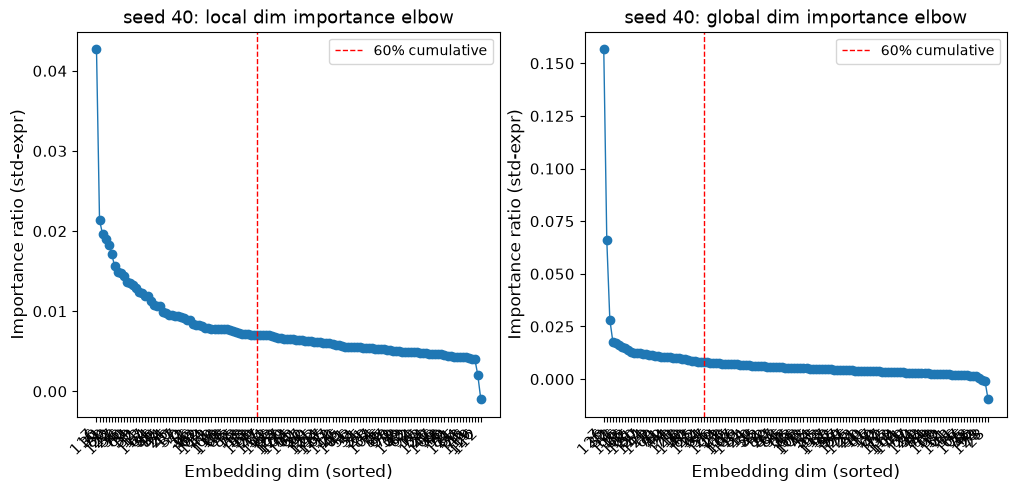

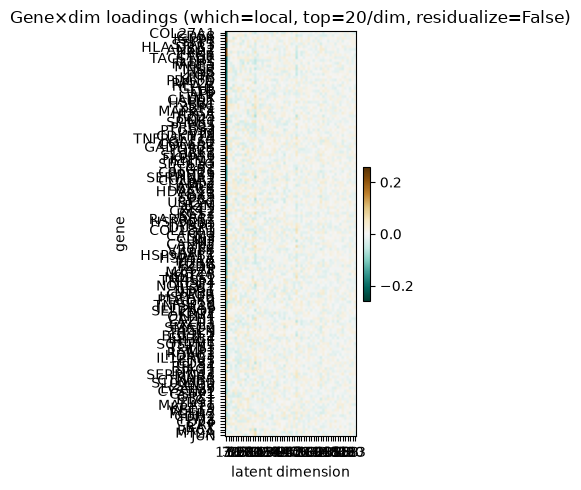

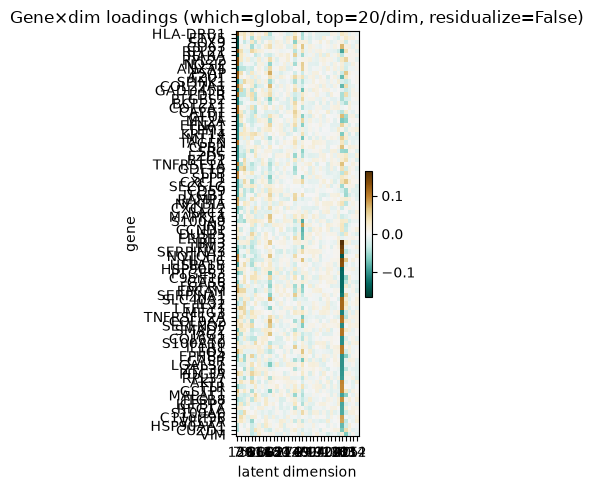

seed 40 local : 146 genes off 54 dims [np.int64(0), np.int64(1), np.int64(2), np.int64(5), np.int64(7), np.int64(11), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18)] ...
seed 40 global:  93 genes off 34 dims [np.int64(2), np.int64(3), np.int64(4), np.int64(7), np.int64(13), np.int64(18), np.int64(25), np.int64(27), np.int64(30), np.int64(34), np.int64(36), np.int64(39)] ...



60% cumulative variance reached with 70 dimensions:
Embedding dimensions (sorted by importance):
[116, 113, 96, 126, 95, 32, 114, 90, 28, 121, 37, 40, 101, 104, 53, 42, 7, 50, 54, 13, 27, 119, 45, 31, 75, 23, 125, 12, 85, 84, 123, 19, 72, 66, 82, 61, 89, 69, 71, 78, 49, 91, 93, 87, 86, 58, 92, 1, 16, 94, 4, 11, 17, 88, 34, 80, 120, 29, 15, 22, 6, 25, 83, 124, 107, 118, 20, 100, 127, 97]

60% cumulative variance reached with 68 dimensions:
Embedding dimensions (sorted by importance):
[45, 7, 75, 50, 121, 12, 93, 28, 101, 13, 116, 1, 95, 69, 88, 19, 103, 4, 41, 104, 84, 37, 62, 115, 79, 126, 0, 97, 29, 53, 74, 16, 71, 61, 105, 92, 57, 96, 111, 68, 72, 66, 42, 35, 2, 40, 32, 87, 112, 91, 27, 78, 17, 123, 119, 82, 89, 114, 11, 55, 99, 15, 106, 34, 22, 108, 113, 23]


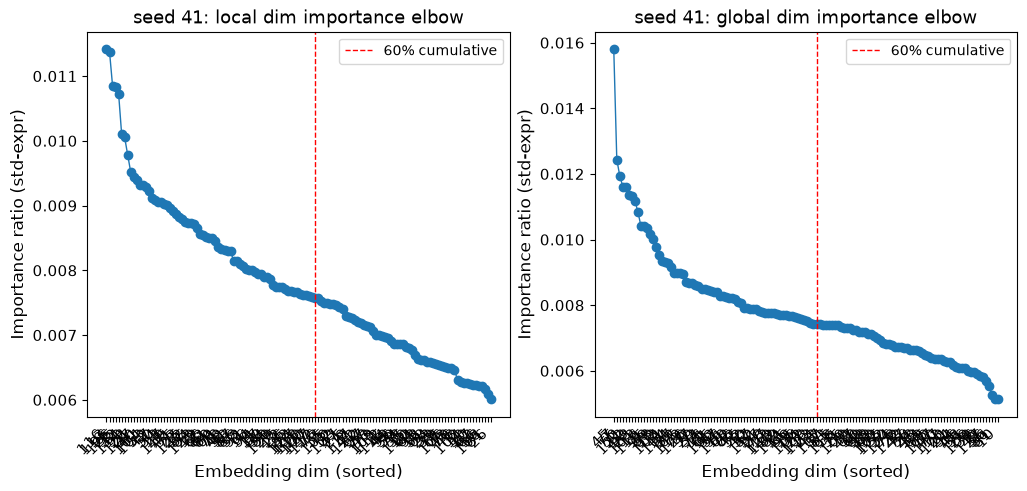

  seed 41 local: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.


  seed 41 global: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.
seed 41 local :   0 genes off 70 dims [np.int64(1), np.int64(4), np.int64(6), np.int64(7), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(20)] ...
seed 41 global:   0 genes off 68 dims [np.int64(0), np.int64(1), np.int64(2), np.int64(4), np.int64(7), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(16), np.int64(17), np.int64(19)] ...



60% cumulative variance reached with 69 dimensions:
Embedding dimensions (sorted by importance):
[80, 77, 83, 66, 13, 36, 16, 32, 46, 60, 111, 112, 75, 88, 74, 100, 73, 63, 43, 8, 30, 120, 34, 26, 37, 40, 94, 38, 11, 104, 91, 17, 82, 69, 67, 7, 62, 33, 47, 106, 49, 9, 35, 109, 85, 89, 42, 12, 115, 23, 45, 102, 44, 15, 5, 14, 39, 126, 90, 61, 81, 122, 78, 51, 52, 127, 68, 108, 59]

60% cumulative variance reached with 68 dimensions:
Embedding dimensions (sorted by importance):
[66, 88, 80, 91, 36, 46, 34, 75, 32, 120, 83, 63, 77, 9, 74, 104, 13, 94, 110, 114, 22, 30, 100, 12, 89, 26, 16, 111, 112, 40, 113, 125, 87, 52, 84, 124, 15, 8, 7, 57, 69, 61, 48, 73, 115, 81, 126, 82, 28, 78, 45, 118, 3, 67, 29, 90, 14, 72, 59, 38, 121, 35, 109, 127, 62, 101, 23, 0]


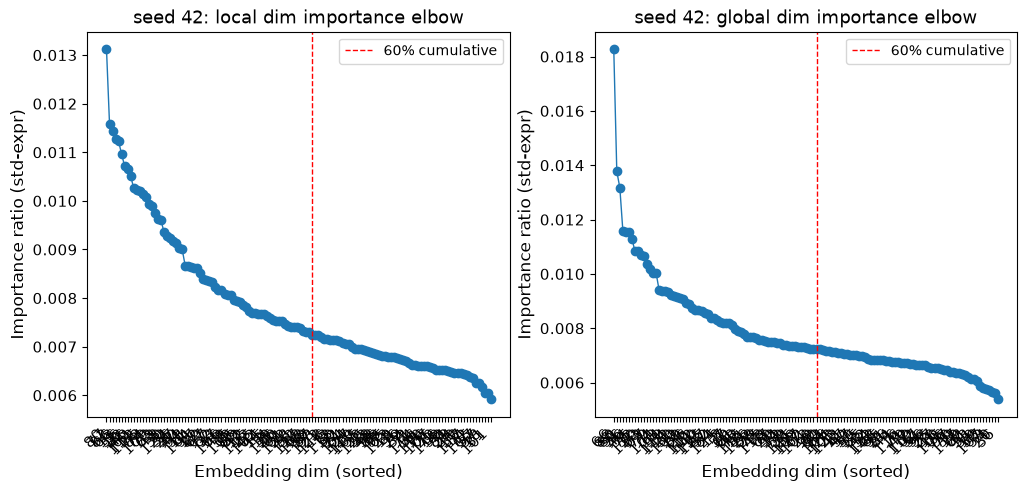

  seed 42 local: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.


  seed 42 global: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.
seed 42 local :   0 genes off 69 dims [np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(23)] ...
seed 42 global:   0 genes off 68 dims [np.int64(0), np.int64(3), np.int64(7), np.int64(8), np.int64(9), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(22), np.int64(23)] ...



60% cumulative variance reached with 57 dimensions:
Embedding dimensions (sorted by importance):
[30, 10, 81, 13, 33, 4, 74, 79, 51, 0, 31, 82, 45, 38, 57, 103, 93, 71, 98, 70, 25, 12, 117, 95, 20, 78, 77, 67, 39, 121, 106, 109, 76, 8, 110, 85, 56, 69, 100, 27, 59, 6, 42, 52, 73, 16, 86, 53, 108, 18, 50, 29, 99, 118, 64, 124, 90]

60% cumulative variance reached with 40 dimensions:
Embedding dimensions (sorted by importance):
[74, 10, 103, 91, 38, 33, 98, 2, 12, 25, 31, 30, 117, 77, 58, 62, 15, 4, 121, 6, 120, 51, 9, 79, 76, 55, 14, 56, 97, 85, 101, 29, 93, 22, 1, 21, 44, 45, 71, 13]


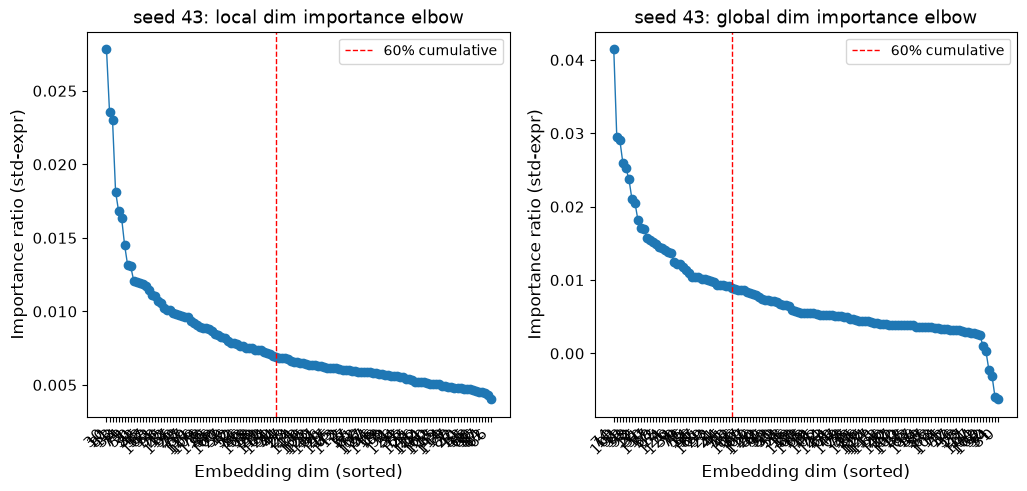

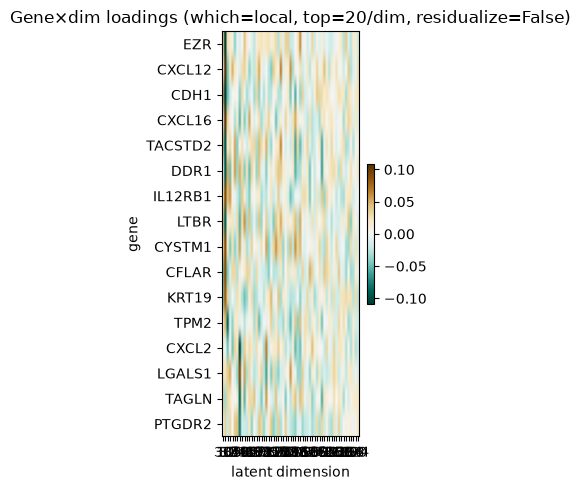

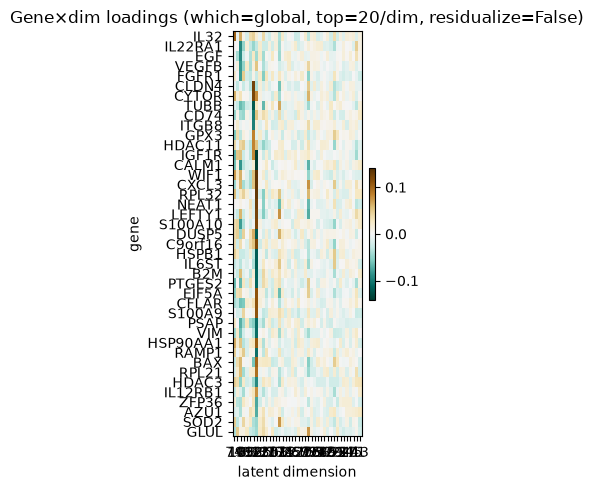

seed 43 local :  16 genes off 57 dims [np.int64(0), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(13), np.int64(16), np.int64(18), np.int64(20), np.int64(25), np.int64(27)] ...
seed 43 global:  41 genes off 40 dims [np.int64(1), np.int64(2), np.int64(4), np.int64(6), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(21), np.int64(22)] ...



60% cumulative variance reached with 69 dimensions:
Embedding dimensions (sorted by importance):
[125, 82, 22, 15, 80, 75, 37, 121, 4, 61, 118, 36, 7, 18, 102, 72, 32, 88, 35, 91, 57, 76, 51, 20, 93, 64, 52, 58, 11, 66, 95, 28, 5, 104, 86, 45, 34, 79, 109, 92, 90, 27, 23, 8, 19, 100, 16, 2, 55, 73, 46, 108, 126, 44, 60, 17, 70, 122, 33, 111, 12, 81, 85, 83, 3, 114, 49, 10, 42]

60% cumulative variance reached with 66 dimensions:
Embedding dimensions (sorted by importance):
[18, 57, 22, 4, 82, 91, 37, 54, 121, 42, 61, 125, 15, 118, 93, 64, 102, 75, 86, 52, 8, 58, 32, 124, 39, 117, 7, 33, 85, 35, 72, 88, 17, 68, 69, 5, 10, 98, 49, 74, 36, 73, 27, 76, 23, 60, 63, 38, 97, 79, 92, 67, 66, 20, 127, 77, 101, 113, 34, 108, 106, 11, 59, 53, 28, 56]


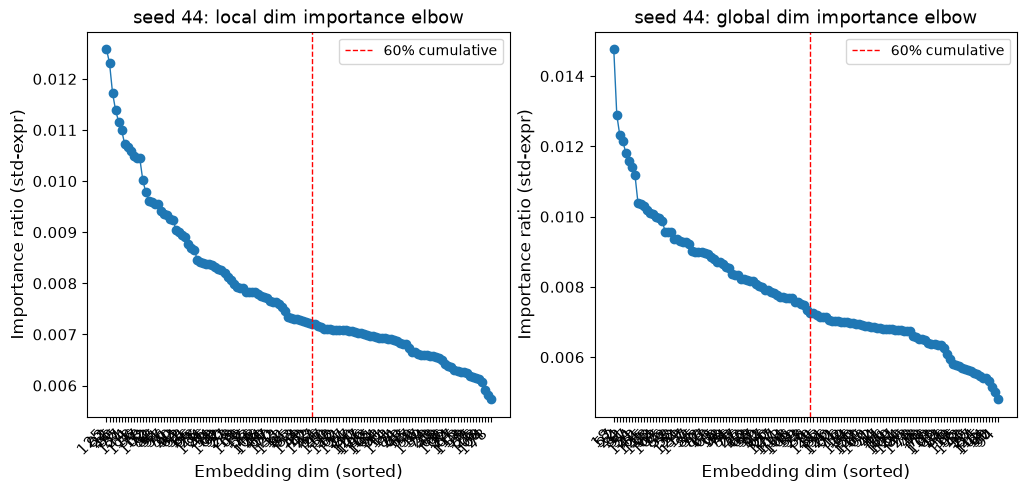

  seed 44 local: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.


  seed 44 global: NO PROGRAM -- No genes passed specificity filter. Lower specificity_min or disable it.
seed 44 local :   0 genes off 69 dims [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(15), np.int64(16), np.int64(17)] ...
seed 44 global:   0 genes off 66 dims [np.int64(4), np.int64(5), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(15), np.int64(17), np.int64(18), np.int64(20), np.int64(22), np.int64(23)] ...

6 of 10 (seed, component) selections produced NO program: [(41, 'global'), (41, 'local'), (42, 'global'), (42, 'local'), (44, 'global'), (44, 'local')]
Those are empty sets, not zero-overlap results -- the loadings carry no dimension-specific signal. Check the arm's own val_concordance_corr before reading anything below.

program sizes  local [146, 0, 0, 16, 0]  global [93, 0, 0, 41, 0]  (pool 217)
Some seeds produced no program; the overlap statistics below average over seeds 

In [16]:
# ---------------------------------------------------------------------------------------------
# THESE FIVE VALUES ARE FIG. 3F's, NOT GUESSES. They are copied from
# scripts/legnini_23/4a_seed_stability_extract.py, whose call site is commented "the same call
# Fig. 3F uses", and confirmed against best_recon/analysis/seed4*_meta.json, which records
# cumulative_cutoff=0.6 and n_top=20 for the published models.
#
# They differ from the legnini23 notebook's settings, and the differences matter:
#
#   cumulative_cutoff 0.6  keeps 41-50 of the 128 dimensions on this dataset -- NOT the 5-7 the
#                          figure's panel labels might suggest. Those labels (57, 87, 48, 103,
#                          70, 33, 3 local; 48, 70, 57, 3, 96 global) are the handful the panel
#                          DISPLAYS; they are a subset of the ~45 actually selected.
#   n_top 20               20 genes per dimension, not legnini23's 3.
#   min_frac 0.1           drops genes expressed in under 10% of cells. legnini23 uses 0.0.
#   enforce_specificity    True, not False. Together with min_frac this is what collapses
#                          ~45 dims x 20 genes into the ~29 local / ~43 global gene programs
#                          best_recon actually recorded -- i.e. the scale of the published
#                          25- and 24-gene lists. Without it the sets would be most of the panel
#                          and every overlap number below would be inflated.
# ---------------------------------------------------------------------------------------------
DIM_CUTOFF = 0.6
N_TOP = 20
ENFORCE_SPECIFICITY = True
SPECIFICITY_MIN = 1.5

# allow_empty=True: with enforce_specificity on, get_genes_dim RAISES "No genes passed
# specificity filter" when no dimension has any gene 1.5x more specific to it than to the
# others -- what noise loadings look like. collect_gene_sets handles that PER (seed,
# component), so a seed with no program contributes an empty set while the others keep theirs.
#
# That distinction matters here: on the gene-masking arm, seed 40 yields 146 local / 93 global
# genes while other seeds yield none. An all-or-nothing catch would report zeros for all five
# and hide it. Note 146 of a 217-gene pool is 67% of everything available -- that is not a gene
# program either, it is noise spread across the panel, and any two such sets overlap heavily by
# construction. Read n_genes below against POOL, not against the published list length.
#
# specificity_min is deliberately NOT lowered to make something come back: that would return the
# top of a noise ranking in the same format as a real program.
df_local_list, df_global_list, dims_used = collect_gene_sets(
    adata,
    models,
    SEEDS,
    layer_key=layer_key,
    dims=None,                  # use the cutoff's selection, not all 128 dims
    cumulative_cutoff=DIM_CUTOFF,
    n_top=N_TOP,
    min_frac=MIN_FRAC,          # set with POOL above; the two must agree
    rank_by="loading_x_sd",
    enforce_specificity=ENFORCE_SPECIFICITY,
    specificity_min=SPECIFICITY_MIN,
    spacing=2,
    allow_empty=True,
    plot=True,
)

# Computed from the results rather than from an exception, so it is per seed, not per arm.
n_local = [len(d) for d in df_local_list]
n_global = [len(d) for d in df_global_list]
HAS_PROGRAMS = any(n_local) or any(n_global)
print(f"\nprogram sizes  local {n_local}  global {n_global}  (pool {POOL})")
if not HAS_PROGRAMS:
    print("NO seed produced a program in either component -- every number below is 0 by that "
          "fact, not by instability.")
elif not (all(n_local) and all(n_global)):
    print("Some seeds produced no program; the overlap statistics below average over seeds that "
          "did and seeds that could not, so read the per-seed sizes above first.")


In [17]:
# The figure's panel labels, and best_recon's own recorded selection, as two reference points.
#
# Dimension INDICES are not expected to reproduce across seeds -- best_recon's five seeds share
# almost none (seed 40 local starts 82, 57, 45; seed 41 starts 0, 74, 73), which is precisely why
# this analysis compares gene sets rather than dimensions. What should reproduce is the COUNT:
# best_recon recorded 41-50 local and 44-52 global dimensions at this cutoff. A seed keeping ~5
# or ~120 means DIM_CUTOFF is not doing what it did there.
FIG_LOCAL_DIMS = [57, 87, 48, 103, 70, 33, 3]    # displayed in panel F, left
FIG_GLOBAL_DIMS = [48, 70, 57, 3, 96]            # displayed in panel F, right
# best_recon/analysis/seed4*_meta.json, over its five seeds. NOTE the cell arm reproduces the
# GLOBAL range but not the LOCAL one (it lands at 57-59 against best_recon's 41-50), despite
# identical cutoff, n_top, min_frac and specificity settings. So the local dimension-importance
# spectrum of these checkpoints is flatter than best_recon's -- worth resolving before the local
# numbers are quoted against the figure.
BEST_RECON_N_DIMS = {"local": (41, 50), "global": (44, 52)}

rows = []
for which, fig_dims in [("local", FIG_LOCAL_DIMS), ("global", FIG_GLOBAL_DIMS)]:
    lo, hi = BEST_RECON_N_DIMS[which]
    for seed in SEEDS:
        d = dims_used[which][seed]
        rows.append({
            "component": which, "seed": seed,
            "n_dims": len(d),
            "in_best_recon_range": lo <= len(d) <= hi,
            "n_genes": len(df_local_list[SEEDS.index(seed)] if which == "local"
                           else df_global_list[SEEDS.index(seed)]),
            "displayed_dims_recovered": f"{len(set(d) & set(fig_dims))}/{len(fig_dims)}",
        })
dims_report = pd.DataFrame(rows).set_index(["component", "seed"])
print(dims_report.to_string())
print()
print("best_recon recorded programs of 29 (local) and 43 (global) genes at these settings;")
print("the published lists are 25 and 24 genes. n_genes above should be the same order.")

                n_dims  in_best_recon_range  n_genes displayed_dims_recovered
component seed                                                               
local     40        54                False      146                      2/7
          41        70                False        0                      1/7
          42        69                False        0                      1/7
          43        57                False       16                      4/7
          44        69                False        0                      4/7
global    40        34                False       93                      2/5
          41        68                False        0                      2/5
          42        68                False        0                      3/5
          43        40                False       41                      0/5
          44        66                False        0                      1/5

best_recon recorded programs of 29 (local) and 43 (global) gene

## Recovery of the published genes

Rows are genes, the first column is the published set, then one column per seed. Genes are
ordered by how many seeds recovered them, so the top block is "reproducible AND published" and
the bottom is seed noise.

`only_truth=False` keeps the union, which also shows what the models found that the figure does
not report; `only_truth=True` restricts to the published genes, which is the recall view.

,truth,40,41,42,43,44
CXCL2,True,True,False,False,True,False
CYSTM1,True,True,False,False,True,False
TPM2,True,True,False,False,True,False
CDH1,False,True,False,False,True,False
DDR1,False,True,False,False,True,False
...,...,...,...,...,...,...
GDF15,True,False,False,False,False,False
H2AZ1,True,False,False,False,False,False
NEAT1,True,False,False,False,False,False
REG1A,True,False,False,False,False,False


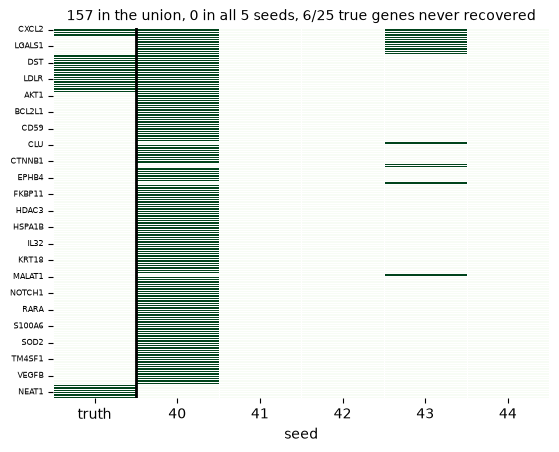

In [18]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth=False)

,truth,40,41,42,43,44
CXCL2,True,True,False,False,True,False
CYSTM1,True,True,False,False,True,False
TPM2,True,True,False,False,True,False
APP,True,True,False,False,False,False
BTG1,True,True,False,False,False,False
CD44,True,True,False,False,False,False
DST,True,True,False,False,False,False
ETV5,True,True,False,False,False,False
GLUL,True,True,False,False,False,False
GPX1,True,True,False,False,False,False


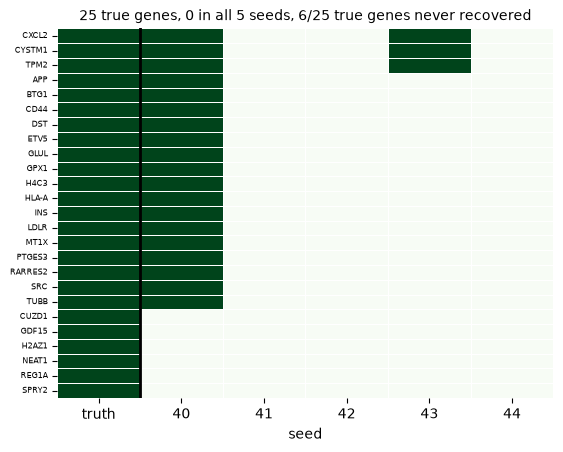

In [19]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth=True)

,truth,40,41,42,43,44
IL32,True,True,False,False,True,False
AZU1,False,True,False,False,True,False
C9orf16,False,True,False,False,True,False
DUSP5,False,True,False,False,True,False
GLUL,False,True,False,False,True,False
...,...,...,...,...,...,...
HSP90AB1,True,False,False,False,False,False
IL10RB,True,False,False,False,False,False
MIF,True,False,False,False,False,False
NDRG1,True,False,False,False,False,False


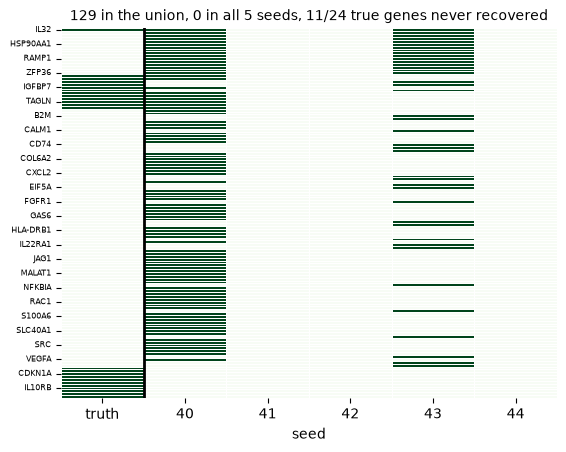

In [20]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth=False)

,truth,40,41,42,43,44
IL32,True,True,False,False,True,False
BTG1,True,True,False,False,False,False
GDF15,True,True,False,False,False,False
GPX3,True,False,False,False,True,False
IGF1R,True,False,False,False,True,False
IGFBP7,True,True,False,False,False,False
IL12RB1,True,False,False,False,True,False
MEG3,True,True,False,False,False,False
RPL22,True,True,False,False,False,False
SPP1,True,True,False,False,False,False


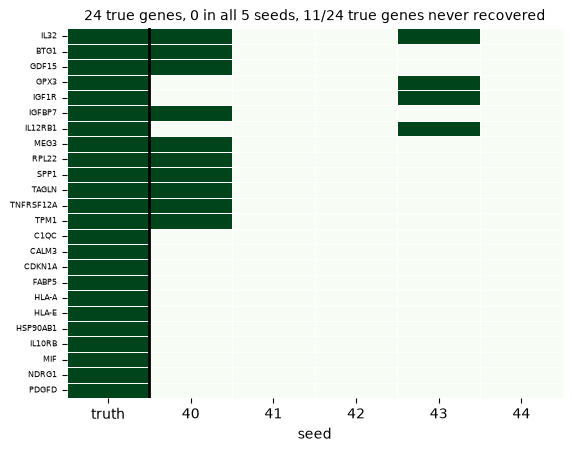

In [21]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth=True)

## Cross-seed stability of the gene sets

Read the observed intersection against its own random expectation, never against zero:
`expected_intersection` is the overlap a random selection of the same set sizes from the same
pool already produces.

In [22]:
exp_intersection = {}
for df_list, component in [(df_local_list, 'local'), (df_global_list, 'global')]:
    sizes = [len(df.index) for df in df_list]
    exp_intersection[component] = {
        "sizes": sizes,
        "observed_all_seeds": len(overlap_matrix(df_list, labels=SEEDS)[1]),
        "expected_all_seeds": expected_intersection(sizes, pool=POOL),
    }
pd.DataFrame(exp_intersection).T

,sizes,observed_all_seeds,expected_all_seeds
local,"[146, 0, 0, 16, 0]",0,0.0
global,"[93, 0, 0, 41, 0]",0,0.0


,group,k,n_subsets,obs_mean,obs_sd,obs_min,obs_max,exp_mean,fold_mean
0,local,2,10,1.1,3.478505,0.0,11.0,1.076498,1.021832
1,local,3,10,0.0,0.000000,0.0,0.0,0.000000,inf
2,local,4,5,0.0,0.000000,0.0,0.0,0.000000,inf
3,local,5,1,0.0,0.000000,0.0,0.0,0.000000,inf
0,global,2,10,1.6,5.059644,0.0,16.0,1.757143,0.910569
1,global,3,10,0.0,0.000000,0.0,0.0,0.000000,inf
2,global,4,5,0.0,0.000000,0.0,0.0,0.000000,inf
3,global,5,1,0.0,0.000000,0.0,0.0,0.000000,inf


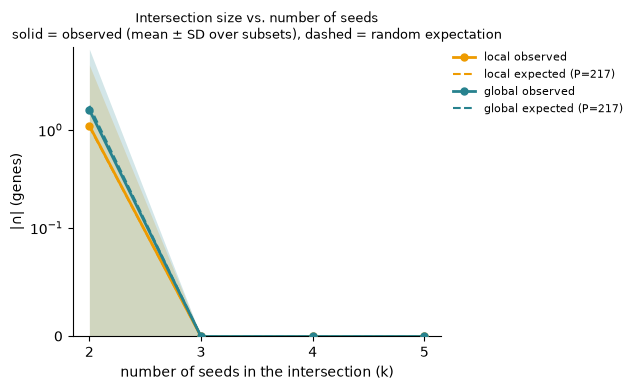

In [23]:
plot_intersection_by_k({"local": df_local_list, "global": df_global_list},
                       pool=POOL, log=True)

,group,k,n_subsets,p_mean,p_median,p_sd,p_min,p_max,obs_mean,exp_mean,fold_mean,method,n_iter
0,local,2,10,0.956880,1.0,0.136358,0.568799,1.0,1.1,1.076498,1.021832,hypergeometric,0
1,local,3,10,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000
2,local,4,5,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000
3,local,5,1,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000
0,global,2,10,0.976511,1.0,0.074280,0.765105,1.0,1.6,1.757143,0.910569,hypergeometric,0
1,global,3,10,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000
2,global,4,5,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000
3,global,5,1,1.000000,1.0,0.000000,1.000000,1.0,0.0,0.000000,inf,monte-carlo,20000


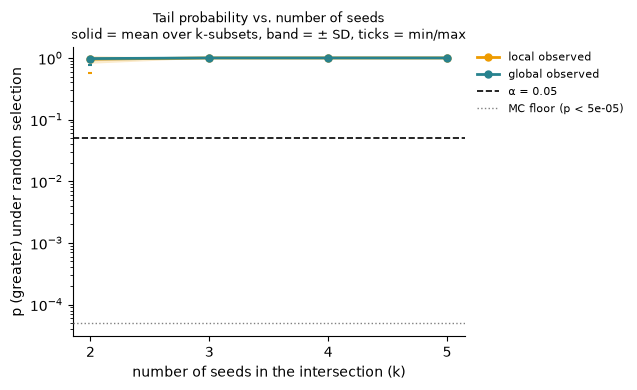

In [24]:
plot_tail_prob_by_k({"local": df_local_list, "global": df_global_list}, pool=POOL)

In [25]:
for name, df_list in [("local", df_local_list), ("global", df_global_list)]:
    overlap, common = overlap_matrix(df_list, labels=SEEDS)
    print(f"--- {name} ---")
    print(overlap)
    print(f"{len(common)} genes in all {len(df_list)} seeds:", sorted(common), "\n")

--- local ---
     40  41  42  43  44
40  146   0   0  11   0
41    0   0   0   0   0
42    0   0   0   0   0
43   11   0   0  16   0
44    0   0   0   0   0
0 genes in all 5 seeds: [] 

--- global ---
    40  41  42  43  44
40  93   0   0  16   0
41   0   0   0   0   0
42   0   0   0   0   0
43  16   0   0  41   0
44   0   0   0   0   0
0 genes in all 5 seeds: [] 



In [26]:
# Recovery of the published genes, WITH its chance baseline.
#
# "recovered by at least one seed" on its own is not a result. Five sets of 30-80 genes drawn
# from a 217-gene pool have a union covering most of that pool, so a published gene lands in it
# with high probability no matter what the model learned. The union row below is therefore
# reported against a hypergeometric p-value: the published list (size T) and the union (size U)
# as two subsets of POOL, which is exactly intersection_tail_probability's two-set exact case.
#
# The all-5-seed core is the number to quote if it is non-empty -- a gene one seed found is not
# a finding -- but on this dataset it is empty, so the union row is all there is, and it needs
# its null to mean anything.
rows = []
for name, df_list, truth in [("local", df_local_list, TRUE_LOCAL_GENES),
                             ("global", df_global_list, TRUE_GLOBAL_GENES)]:
    sets = [set(map(str, d.index)) for d in df_list]
    truth = set(map(str, truth))
    core = set.intersection(*sets)
    union = set.union(*sets)

    for scope, sel in [("all-5-seed core", core), ("union over 5 seeds", union)]:
        hit = sel & truth
        # Two subsets of POOL -> exact hypergeometric, no Monte-Carlo floor.
        r = (intersection_tail_probability([len(sel), len(truth)], POOL, len(hit))
             if len(sel) >= 1 else None)
        rows.append({
            "component": name,
            "scope": scope,
            "n_selected": len(sel),
            "frac_of_pool": len(sel) / POOL,
            "published_recovered": f"{len(hit)}/{len(truth)}",
            "expected_by_chance": round(r["expected"], 2) if r else 0.0,
            "fold": round(r["fold_change"], 2) if r and r["expected"] > 0 else float("nan"),
            "p_greater": f"{r['p_value']:.3g}" if r else "n/a",
        })
recovery = pd.DataFrame(rows).set_index(["component", "scope"])
print(recovery.to_string())
print()
print("Read `fold` and `p_greater`, not `published_recovered`. A fold near 1 means the overlap is")
print("what selecting that many genes from this pool would give at random, whatever its raw count.")
print("`frac_of_pool` near 1 means the selection is most of the pool, so a high raw count is")
print("arithmetic rather than a finding -- that is the gene-masking arm's failure mode.")

# Persist the sets so this can be re-analysed without another GPU run.
for name, df_list in [("local", df_local_list), ("global", df_global_list)]:
    for seed, d in zip(SEEDS, df_list):
        pd.Series(sorted(map(str, d.index)), name="gene").to_csv(
            RESULTS_DIR / f"gene_set_{name}_seed{seed}.csv", index=False)
recovery.to_csv(RESULTS_DIR / "published_gene_recovery.csv")
print(f"\nwrote gene sets + published_gene_recovery.csv to {RESULTS_DIR}")

                              n_selected  frac_of_pool published_recovered  expected_by_chance  fold p_greater
component scope                                                                                               
local     all-5-seed core              0      0.000000                0/25                0.00   NaN       n/a
          union over 5 seeds         151      0.695853               19/25               17.40  1.09     0.312
global    all-5-seed core              0      0.000000                0/24                0.00   NaN       n/a
          union over 5 seeds         118      0.543779               13/24               13.05  1.00     0.596

Read `fold` and `p_greater`, not `published_recovered`. A fold near 1 means the overlap is
what selecting that many genes from this pool would give at random, whatever its raw count.
`frac_of_pool` near 1 means the selection is most of the pool, so a high raw count is
arithmetic rather than a finding -- that is the gene-masking arm


wrote gene sets + published_gene_recovery.csv to /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25/rec_seed_stablity_gene


In [27]:
# Which genes both decoders pick up, for one seed. The local/global split is only interpretable
# per model, not pooled over seeds.
split = local_global_split(df_local_list[-1], df_global_list[-1])
print(f"seed {SEEDS[-1]}")
for k, v in split.items():
    print(f"  {k:14s} ({len(v):3d}): {v}")

seed 44
  shared         (  0): []
  unique_local   (  0): []
  unique_global  (  0): []


## Cross-seed comparison of the loading geometry

The matching-free statistics (which do not depend on pairing dimensions between seeds, and are
therefore immune to the `1 / std(x_gene)` factor that a standardized loading shares across
seeds) are not computed in the notebook -- they are three scripts, chained as one SLURM job:

```bash
SPEC=melton25 sbatch scripts/legnini_23/run_seed_stability.sh
```

Outputs land in `figures/melton25/seed_stability/`. Read `stability_summary.csv` against its own
`shuffled_dim_pairing` rows, not against zero: on legnini23 the top-20 gene Jaccard of 0.54
turned out to equal its shuffled-dimension control of 0.55. `geom_topk_artifact.csv` quantifies
that directly.